# 01 · A Gaussian beam, built function by function

This companion notebook follows the same physical story as `01_gaussian.ipynb`, but defines each small function immediately before the experiment needs it. The goal is to connect implementation details to the optical quantity they calculate.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Define a Gaussian field profile

We want a function that accepts an axis, a center, and a full width at half maximum (FWHM). The conversion below maps FWHM to the Gaussian scale parameter. The returned profile has unit peak.

In [ ]:
def gaussian(x, mean, fwhm):
    """Return a unit-peak Gaussian field profile."""
    sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
    return np.exp(-((x - mean) / (np.sqrt(2) * sigma)) ** 2)


We can now evaluate the field on a transverse coordinate grid. All positions and widths must use the same units.

In [ ]:
dx_m = 1e-6
window_m = 400e-6
x_m = np.arange(-window_m / 2, window_m / 2, dx_m)
fwhm_m = 40e-6
field = gaussian(x_m, mean=0.0, fwhm=fwhm_m)
intensity = np.abs(field) ** 2


## 2. Define an intensity-weighted RMS width

A beam width should describe where the optical power lies, so use intensity weights `|field|²`. The weighted center is the first moment, and the RMS width is the square root of the weighted variance. Normalizing the weights makes the result independent of overall field amplitude.

In [ ]:
def rms_width(field, x):
    """Return the intensity-weighted RMS width in the units of x."""
    x = np.asarray(x)
    intensity = np.abs(field) ** 2
    weights = intensity / intensity.sum()
    center = np.sum(weights * x)
    return np.sqrt(np.sum(weights * (x - center) ** 2))


Apply the measurement to the field. Because `gaussian` describes the field envelope and `rms_width` weights by intensity, the expected RMS width below includes the extra narrowing from squaring the Gaussian.

In [ ]:
sigma_field_m = rms_width(field, x_m)
sigma_expected_m = fwhm_m / (4 * np.sqrt(np.log(2)))
print(f"Measured RMS intensity width: {sigma_field_m * 1e6:.3f} µm")
print(f"Expected for this field:      {sigma_expected_m * 1e6:.3f} µm")


## 3. Make the measurement reusable

The functions above mirror the package API used in the companion notebook. Keeping the function definitions here makes the mathematics visible; placing each definition beside its first use also makes clear why the function exists. Try moving the beam center or changing the window to inspect how the sampled moments respond.

## Original plot code (verbatim)

The following code cells and saved outputs are copied unchanged from the cited notebook cells. Some source cells rely on variables established earlier in their original notebook.


From `paper/fwhm_rms.ipynb`, cell 0.


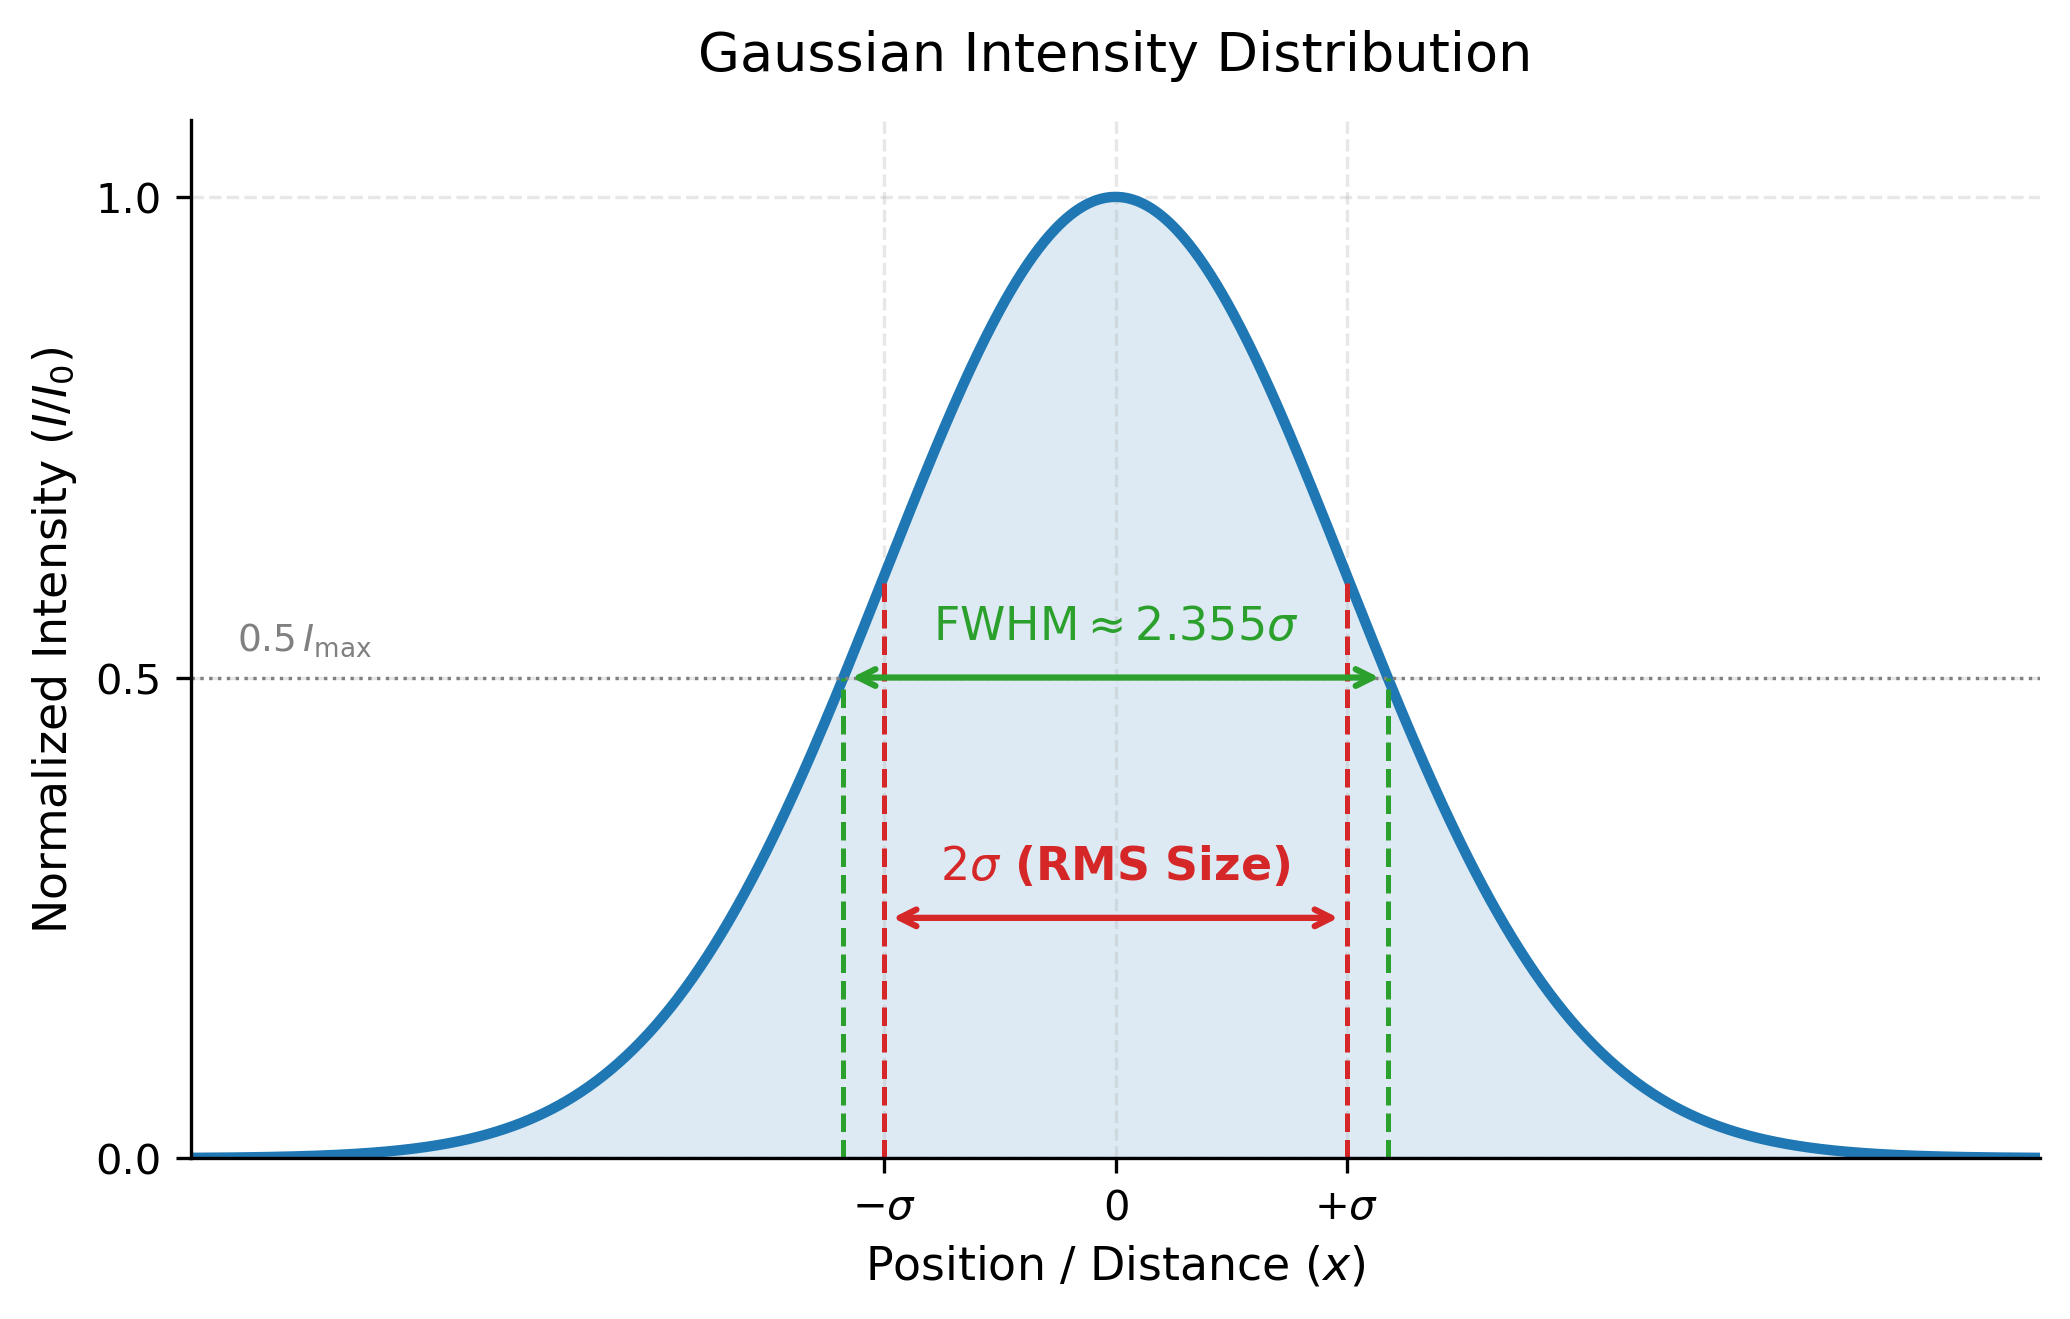

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Define Gaussian parameters
sigma = 1.0
fwhm = 2.35482 * sigma
half_max = 0.5

# Generate x and y data
x = np.linspace(-4 * sigma, 4 * sigma, 1000)
y = np.exp(-(x**2) / (2 * sigma**2))

# Create the figure
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)

# Plot the Gaussian profile
ax.plot(x, y, color="#1f77b4", linewidth=2.5, label="Gaussian Intensity")
ax.fill_between(x, y, color="#1f77b4", alpha=0.15)

# --- 1. Highlight RMS Beam Size (\sigma) ---
ax.vlines(
    [-sigma, sigma],
    0,
    np.exp(-0.5),
    color="#d62728",
    linestyle="--",
    linewidth=1.2,
)
ax.annotate(
    "",
    xy=(-sigma, 0.25),
    xytext=(sigma, 0.25),
    arrowprops=dict(arrowstyle="<->", color="#d62728", lw=1.5),
)
ax.text(
    0,
    0.28,
    r"$2\sigma$ (RMS Size)",
    color="#d62728",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold",
)

# --- 2. Highlight FWHM ---
ax.axhline(half_max, color="gray", linestyle=":", linewidth=0.8)
ax.vlines(
    [-fwhm / 2, fwhm / 2],
    0,
    half_max,
    color="#2ca02c",
    linestyle="--",
    linewidth=1.2,
)
ax.annotate(
    "",
    xy=(-fwhm / 2, half_max),
    xytext=(fwhm / 2, half_max),
    arrowprops=dict(arrowstyle="<->", color="#2ca02c", lw=1.5),
)
ax.text(
    0,
    half_max + 0.03,
    r"$\mathrm{FWHM} \approx 2.355\sigma$",
    color="#2ca02c",
    ha="center",
    va="bottom",
    fontsize=11,
    fontweight="bold",
)

# Add half-maximum marker text on y-axis
ax.text(
    -3.8,
    half_max + 0.02,
    r"$0.5\,I_{\mathrm{max}}$",
    va="bottom",
    ha="left",
    fontsize=9,
    color="gray",
)

# Formatting axes
ax.set_title("Gaussian Intensity Distribution", fontsize=13, pad=12)
ax.set_xlabel("Position / Distance ($x$)", fontsize=11)
ax.set_ylabel("Normalized Intensity ($I / I_0$)", fontsize=11)

ax.set_xlim(-4 * sigma, 4 * sigma)
ax.set_ylim(0, 1.08)

# Standard tick locations without FWHM labels
ax.set_xticks([-sigma, 0, sigma])
ax.set_xticklabels([r"$-\sigma$", r"$0$", r"$+\sigma$"])
ax.set_yticks([0, 0.5, 1.0])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()